<a href="https://colab.research.google.com/github/anshpatel-177/Plant-Disease-Detection/blob/main/Plant_Disease_Detection_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!git clone https://github.com/spMohanty/PlantVillage-Dataset.git

fatal: destination path 'PlantVillage-Dataset' already exists and is not an empty directory.


In [ ]:
import os

dataset_path = "/content/PlantVillage-Dataset/raw/color"

print("Dataset folder exists:", os.path.exists(dataset_path))

classes = os.listdir(dataset_path)
print("Total classes:", len(classes))
print(classes[:10])

Dataset folder exists: True
Total classes: 38
['Tomato___Septoria_leaf_spot', 'Pepper,_bell___healthy', 'Corn_(maize)___healthy', 'Peach___Bacterial_spot', 'Orange___Haunglongbing_(Citrus_greening)', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Strawberry___healthy', 'Tomato___Leaf_Mold', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot']


In [ ]:
tomato_classes = [
    folder for folder in classes
    if folder.startswith("Tomato")
]

print("Total Tomato Classes:", len(tomato_classes))

for cls in sorted(tomato_classes):
    print(cls)

Total Tomato Classes: 10
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


In [ ]:
import os

dataset_path = "/content/PlantVillage-Dataset/raw/color"

tomato_classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if folder.startswith("Tomato")
])

total_images = 0

for cls in tomato_classes:
    class_path = os.path.join(dataset_path, cls)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"{cls}: {len(images)} images")
    total_images += len(images)

print("\nTotal Tomato Images:", total_images)

Tomato___Bacterial_spot: 2127 images
Tomato___Early_blight: 1000 images
Tomato___Late_blight: 1909 images
Tomato___Leaf_Mold: 952 images
Tomato___Septoria_leaf_spot: 1771 images
Tomato___Spider_mites Two-spotted_spider_mite: 1676 images
Tomato___Target_Spot: 1404 images
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357 images
Tomato___Tomato_mosaic_virus: 373 images
Tomato___healthy: 1591 images

Total Tomato Images: 18160


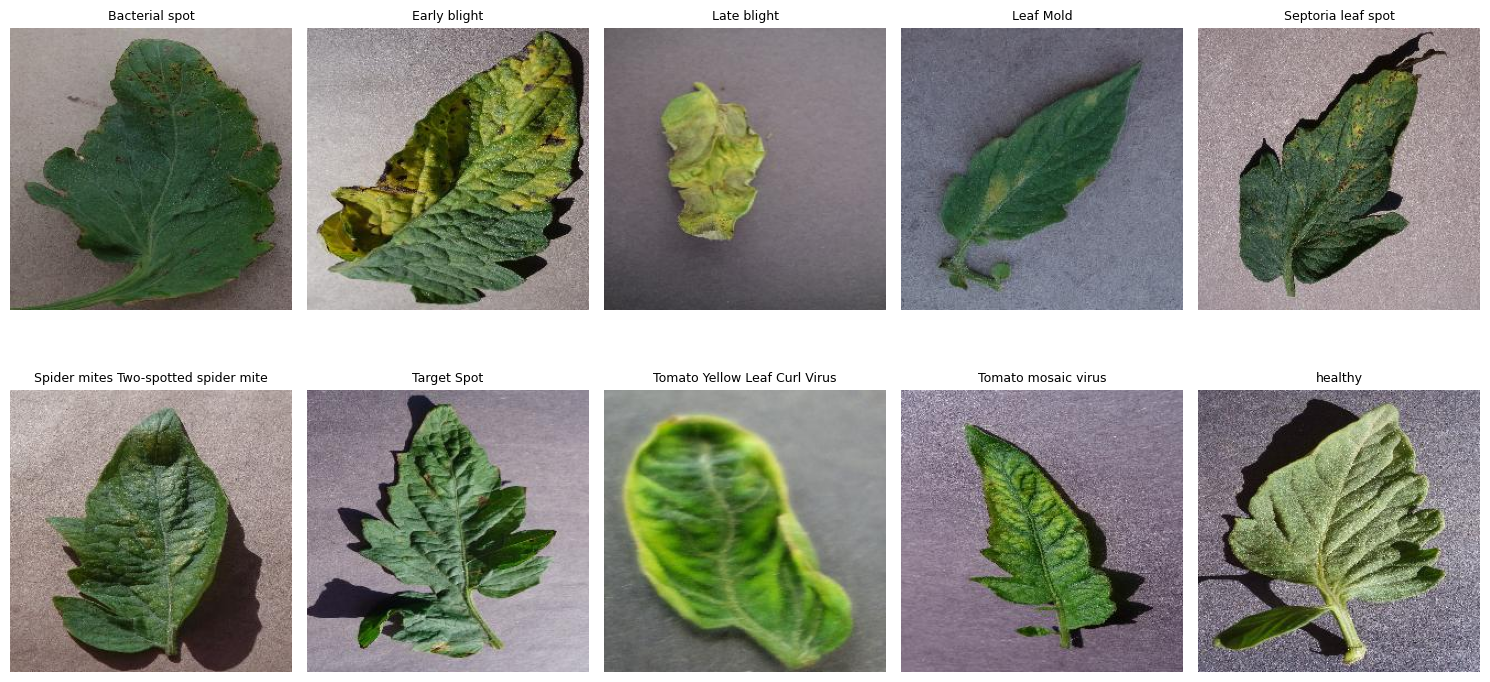

In [ ]:
import matplotlib.pyplot as plt
import random
from PIL import Image

plt.figure(figsize=(15, 8))

for i, cls in enumerate(tomato_classes):
    class_path = os.path.join(dataset_path, cls)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    random_image = random.choice(images)
    img = Image.open(os.path.join(class_path, random_image))

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)

    # Make class name easier to read
    title = cls.replace("Tomato___", "").replace("_", " ")
    plt.title(title, fontsize=9)

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
import os

dataset_path = "/content/PlantVillage-Dataset/raw/color"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

tomato_classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if folder.startswith("Tomato")
])

print("Classes:", len(tomato_classes))
print(*tomato_classes, sep="\n")

Classes: 10
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


In [ ]:
import shutil

tomato_path = "/content/tomato_dataset"

if os.path.exists(tomato_path):
    shutil.rmtree(tomato_path)

os.makedirs(tomato_path)

for cls in tomato_classes:
    source = os.path.join(dataset_path, cls)
    destination = os.path.join(tomato_path, cls)

    shutil.copytree(source, destination)

print("Tomato dataset created successfully!")

Tomato dataset created successfully!


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    tomato_path,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 18160 files belonging to 10 classes.
Using 12712 files for training.


In [ ]:
remaining_ds = tf.keras.utils.image_dataset_from_directory(
    tomato_path,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 18160 files belonging to 10 classes.
Using 5448 files for validation.


In [ ]:
remaining_batches = tf.data.experimental.cardinality(remaining_ds).numpy()

val_batches = remaining_batches // 2

val_ds = remaining_ds.take(val_batches)
test_ds = remaining_ds.skip(val_batches)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 398
Validation batches: 85
Testing batches: 86


In [ ]:
class_names = train_ds.class_names

print("Number of Classes:", len(class_names))

for i, name in enumerate(class_names):
    print(i, "→", name)

Number of Classes: 10
0 → Tomato___Bacterial_spot
1 → Tomato___Early_blight
2 → Tomato___Late_blight
3 → Tomato___Leaf_Mold
4 → Tomato___Septoria_leaf_spot
5 → Tomato___Spider_mites Two-spotted_spider_mite
6 → Tomato___Target_Spot
7 → Tomato___Tomato_Yellow_Leaf_Curl_Virus
8 → Tomato___Tomato_mosaic_virus
9 → Tomato___healthy


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Datasets optimized successfully!")

Datasets optimized successfully!


In [ ]:
from tensorflow.keras import layers, models

num_classes = len(class_names)

model_baseline = models.Sequential([

    # Convert pixel values from 0-255 to 0-1
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into one-dimensional form
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Output layer
    layers.Dense(num_classes, activation='softmax')
])

model_baseline.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_baseline.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Baseline CNN compiled successfully!")

Baseline CNN compiled successfully!


In [ ]:
EPOCHS = 15

history_baseline = model_baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.7144 - loss: 0.8380 - val_accuracy: 0.8301 - val_loss: 0.4912
Epoch 2/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.8740 - loss: 0.3675 - val_accuracy: 0.8842 - val_loss: 0.3157
Epoch 3/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9176 - loss: 0.2425 - val_accuracy: 0.8765 - val_loss: 0.3656
Epoch 4/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9384 - loss: 0.1806 - val_accuracy: 0.9154 - val_loss: 0.2459
Epoch 5/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9583 - loss: 0.1222 - val_accuracy: 0.9324 - val_loss: 0.1996
Epoch 6/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9658 - loss: 0.1015 - val_accuracy: 0.9107 - val_loss: 0.2604
Epoch 7/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9782 - loss: 0.0628 - val_accuracy: 0.9129 - val_loss: 0.3088
Epoch 8/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9786 - loss: 0.0609 - val_

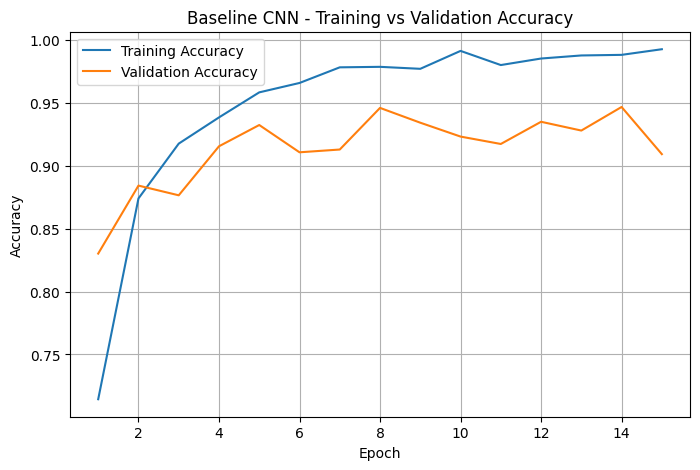

In [ ]:
import matplotlib.pyplot as plt

train_acc = history_baseline.history['accuracy']
val_acc = history_baseline.history['val_accuracy']

train_loss = history_baseline.history['loss']
val_loss = history_baseline.history['val_loss']

epochs_range = range(1, len(train_acc) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Baseline CNN - Training vs Validation Accuracy')
plt.legend()
plt.grid()

plt.show()

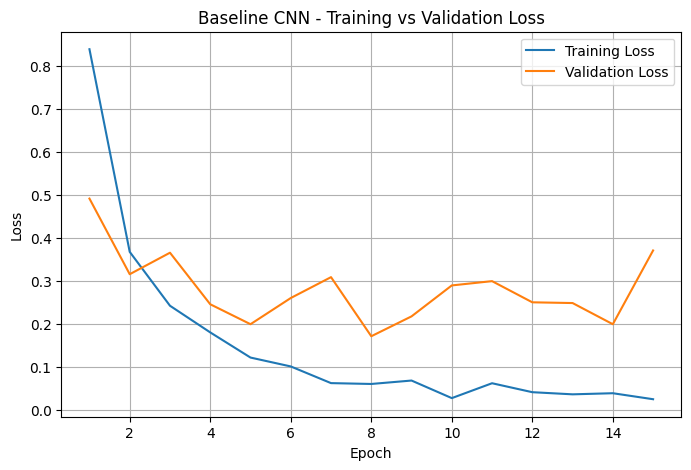

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Baseline CNN - Training vs Validation Loss')
plt.legend()
plt.grid()

plt.show()

In [ ]:
baseline_test_loss, baseline_test_accuracy = model_baseline.evaluate(test_ds)

print(f"Baseline Test Accuracy: {baseline_test_accuracy * 100:.2f}%")
print(f"Baseline Test Loss: {baseline_test_loss:.4f}")

86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9076 - loss: 0.4349
Baseline Test Accuracy: 90.76%
Baseline Test Loss: 0.4349


In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

print("Image Augmentation created successfully!")

Image Augmentation created successfully!


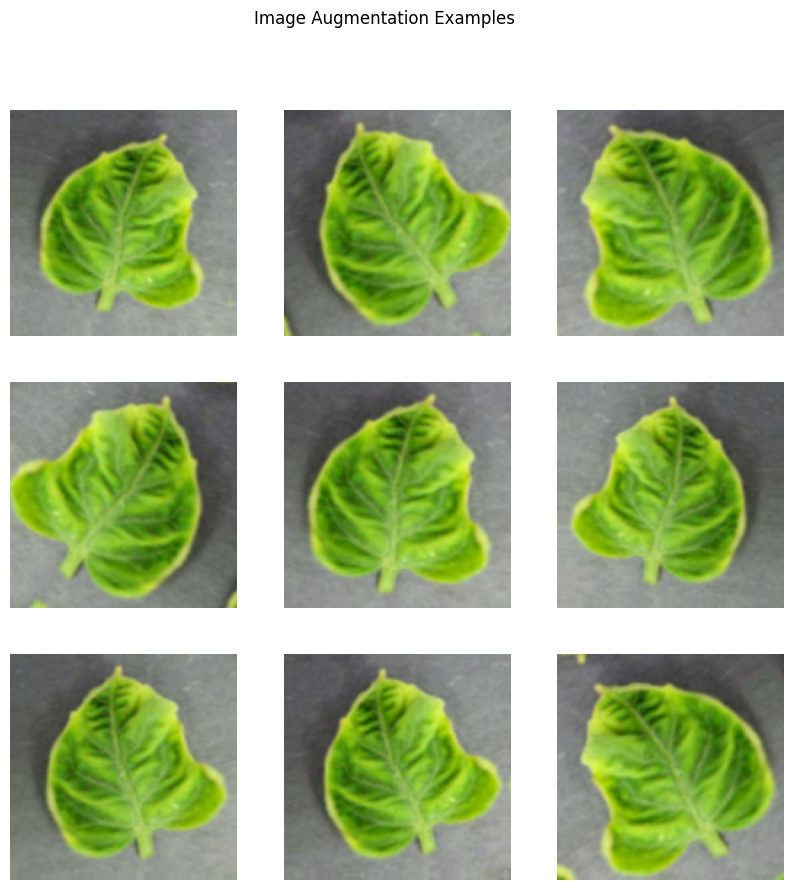

In [ ]:
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):
    image = images[0]

    plt.figure(figsize=(10, 10))

    for i in range(9):
        augmented_image = data_augmentation(
            tf.expand_dims(image, 0),
            training=True
        )

        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented_image[0].numpy().astype("uint8"))
        plt.axis("off")

    plt.suptitle("Image Augmentation Examples")
    plt.show()

In [ ]:
from tensorflow.keras import layers, models

# Create a fresh augmentation layer
data_augmentation_model = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
], name="data_augmentation")

# Create CNN model
model_augmented = models.Sequential([

    # Explicit input layer
    layers.Input(shape=(128, 128, 3)),

    # Image augmentation
    data_augmentation_model,

    # Normalize pixel values
    layers.Rescaling(1./255),

    # CNN Block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # CNN Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # CNN Block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),

    # Output layer
    layers.Dense(num_classes, activation='softmax')
])

model_augmented.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_augmented.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Augmented CNN compiled successfully!")

Augmented CNN compiled successfully!


In [ ]:
EPOCHS = 15

history_augmented = model_augmented.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.6420 - loss: 1.0495 - val_accuracy: 0.8195 - val_loss: 0.5209
Epoch 2/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.8249 - loss: 0.5043 - val_accuracy: 0.8577 - val_loss: 0.4076
Epoch 3/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.8652 - loss: 0.3860 - val_accuracy: 0.8621 - val_loss: 0.4070
Epoch 4/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.8968 - loss: 0.2941 - val_accuracy: 0.8316 - val_loss: 0.4941
Epoch 5/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.9121 - loss: 0.2522 - val_accuracy: 0.8710 - val_loss: 0.3778
Epoch 6/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.9187 - loss: 0.2278 - val_accuracy: 0.9070 - val_loss: 0.2668
Epoch 7/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.9329 - loss: 0.1920 - val_accuracy: 0.9324 - val_loss: 0.1983
Epoch 8/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.9396 - loss: 0.1669 - 

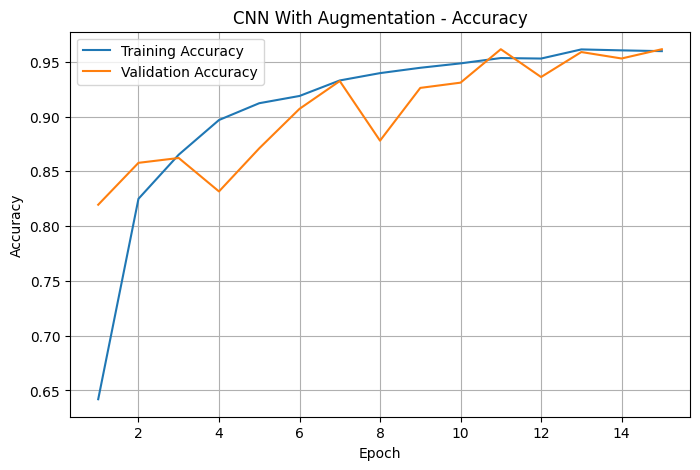

In [ ]:
aug_train_acc = history_augmented.history['accuracy']
aug_val_acc = history_augmented.history['val_accuracy']

epochs_range = range(1, len(aug_train_acc) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    aug_train_acc,
    label='Training Accuracy'
)

plt.plot(
    epochs_range,
    aug_val_acc,
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN With Augmentation - Accuracy')
plt.legend()
plt.grid()

plt.show()

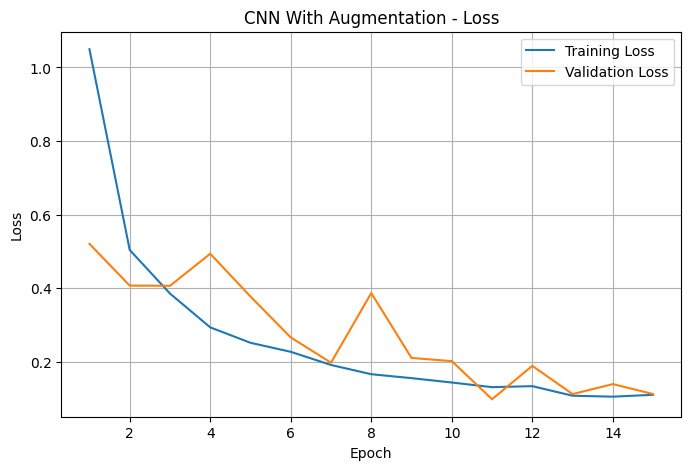

In [ ]:
aug_train_loss = history_augmented.history['loss']
aug_val_loss = history_augmented.history['val_loss']

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    aug_train_loss,
    label='Training Loss'
)

plt.plot(
    epochs_range,
    aug_val_loss,
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN With Augmentation - Loss')
plt.legend()
plt.grid()

plt.show()

In [ ]:
aug_test_loss, aug_test_accuracy = model_augmented.evaluate(test_ds)

print(
    f"Augmented CNN Test Accuracy: "
    f"{aug_test_accuracy * 100:.2f}%"
)

print(
    f"Augmented CNN Test Loss: "
    f"{aug_test_loss:.4f}"
)

86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9619 - loss: 0.1242
Augmented CNN Test Accuracy: 96.19%
Augmented CNN Test Loss: 0.1242


In [ ]:
print("========== MODEL COMPARISON ==========")

print(
    f"Without Augmentation Accuracy : "
    f"{baseline_test_accuracy * 100:.2f}%"
)

print(
    f"With Augmentation Accuracy    : "
    f"{aug_test_accuracy * 100:.2f}%"
)

difference = (
    aug_test_accuracy - baseline_test_accuracy
) * 100

print(
    f"Accuracy Difference           : "
    f"{difference:+.2f}%"
)

========== MODEL COMPARISON ==========
Without Augmentation Accuracy : 90.76%
With Augmentation Accuracy    : 96.19%
Accuracy Difference           : +5.43%


In [ ]:
print("Final model:", 'final_model' in globals())
print("Augmented model:", 'model_augmented' in globals())
print("Baseline model:", 'model_baseline' in globals())

Final model: False
Augmented model: True
Baseline model: True


In [ ]:
model_augmented.save("/content/plant_disease_model.keras")
print("Augmented model saved successfully!")

Augmented model saved successfully!


In [ ]:
import json

with open("/content/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class names saved successfully!")

Class names saved successfully!


In [ ]:
import os

print(
    "Model exists:",
    os.path.exists("/content/plant_disease_model.keras")
)

print(
    "Class names exists:",
    os.path.exists("/content/class_names.json")
)

Model exists: True
Class names exists: True


In [ ]:
from google.colab import files

files.download("/content/plant_disease_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("/content/class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Augmented model:", 'model_augmented' in globals())
print("Baseline model:", 'model_baseline' in globals())

Augmented model: True
Baseline model: True


In [ ]:
final_model = model_augmented
print("Final model selected successfully!")

Final model selected successfully!


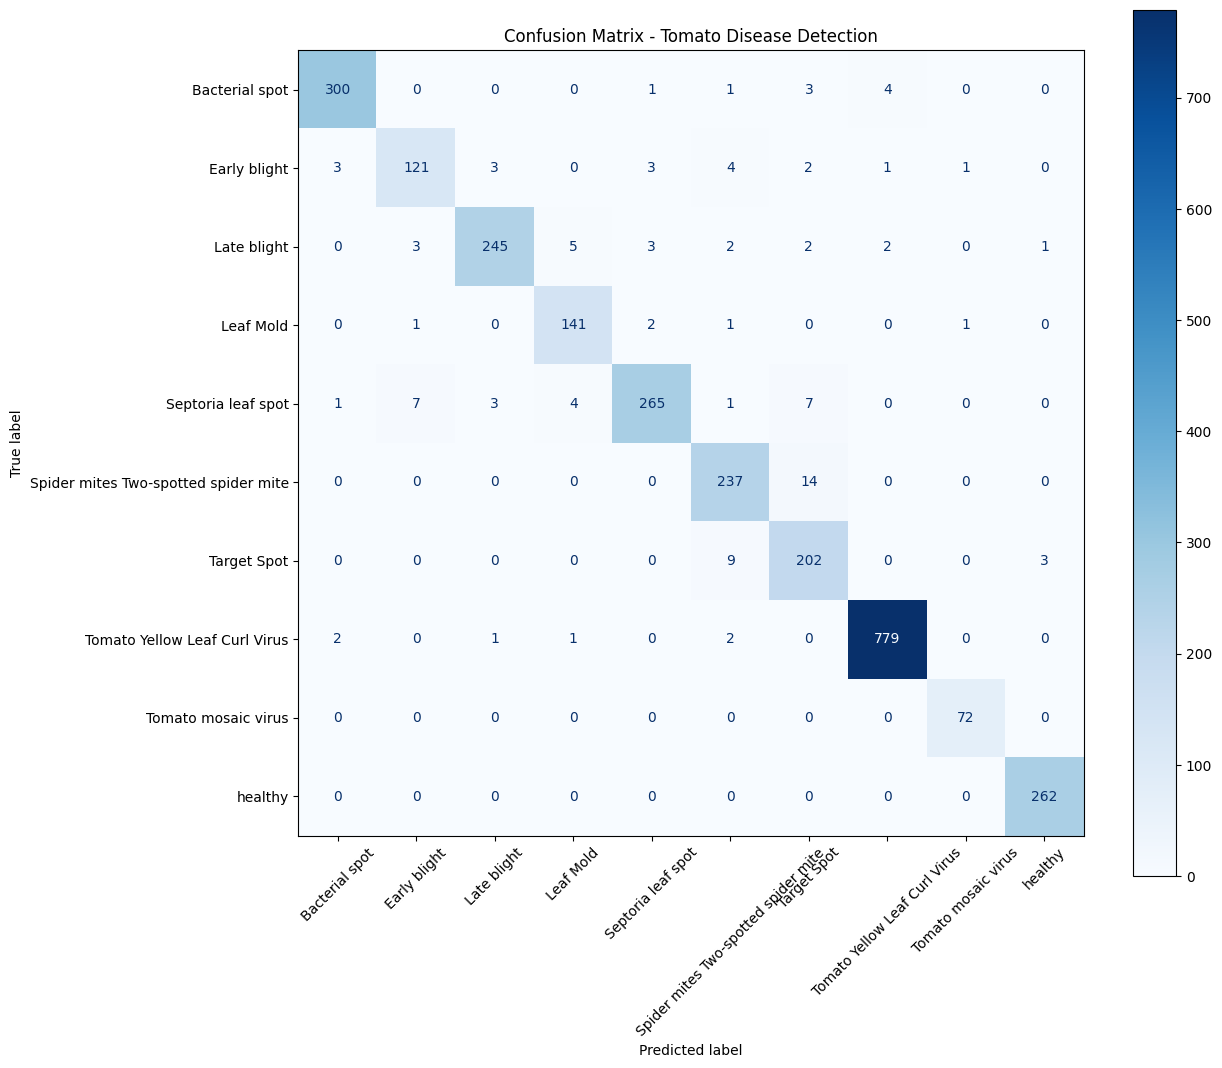

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = final_model.predict(
        images,
        verbose=0
    )

    y_true.extend(labels.numpy())
    y_pred.extend(
        np.argmax(predictions, axis=1)
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

cm = confusion_matrix(y_true, y_pred)

clean_names = [
    name.replace("Tomato___", "").replace("_", " ")
    for name in class_names
]

fig, ax = plt.subplots(figsize=(13, 11))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=clean_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix - Tomato Disease Detection")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=clean_names,
        digits=4
    )
)

CLASSIFICATION REPORT

                                      precision    recall  f1-score   support

                      Bacterial spot     0.9804    0.9709    0.9756       309
                        Early blight     0.9167    0.8768    0.8963       138
                         Late blight     0.9722    0.9316    0.9515       263
                           Leaf Mold     0.9338    0.9658    0.9495       146
                  Septoria leaf spot     0.9672    0.9201    0.9431       288
Spider mites Two-spotted spider mite     0.9222    0.9442    0.9331       251
                         Target Spot     0.8783    0.9439    0.9099       214
       Tomato Yellow Leaf Curl Virus     0.9911    0.9924    0.9917       785
                 Tomato mosaic virus     0.9730    1.0000    0.9863        72
                             healthy     0.9850    1.0000    0.9924       262

                            accuracy                         0.9619      2728
                           macro avg   

In [ ]:
test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

print("\nFINAL MODEL RESULTS")
print("--------------------------")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9619 - loss: 0.1206

FINAL MODEL RESULTS
--------------------------
Test Accuracy : 96.19%
Test Loss     : 0.1206


In [ ]:
final_model.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,917,792 (37.83 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,611,862 (25.22 MB)